# Deep Learning Questions — Backprop by Hand, Networks by NumPy

DL rounds test whether you understand backprop as *calculus you could do on a whiteboard* — not whether you can call `.fit()`. So this notebook does the real thing: a two-layer neural network implemented in pure NumPy, trained live on real data, with the gradients written out by hand. If you can reproduce this notebook's network from memory, the DL round stops being scary.

## Q1 — The Perceptron to MLP Step: What Nonlinearity Buys

A linear stack of layers collapses to one linear map (W₂W₁x = Wx). The **nonlinearity** between layers is the entire reason depth works: it lets the network carve the input space into many regions. Classic interview factoid — a network of ReLUs with d inputs, one hidden layer of h units, creates a piecewise-linear function with up to O(hᵈ) linear regions; depth multiplies regions *exponentially* cheaper than width.

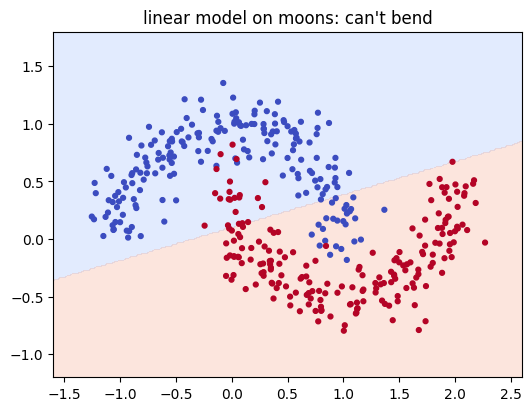

one straight cut cannot separate interleaved moons — nonlinearity is not optional


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=400, noise=0.15, random_state=0)
y = y.reshape(-1, 1)

# linear boundary attempt: logistic regression on (x1, x2)
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression().fit(X, y.ravel())

def plot_db(ax, model, title):
    xx, yy = np.meshgrid(np.linspace(-1.6, 2.6, 200), np.linspace(-1.2, 1.8, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = (model.predict_proba(grid)[:, 1] if hasattr(model, "predict_proba")
         else model(grid).ravel()).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0.5, alpha=0.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y.ravel(), s=12, cmap="coolwarm")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(5.2, 4), constrained_layout=True)
plot_db(ax, lr, "linear model on moons: can't bend")
plt.show()
print("one straight cut cannot separate interleaved moons — nonlinearity is not optional")

## Q2 — The Two-Layer Network in Pure NumPy

The architecture: input → hidden (tanh) → output (sigmoid) → binary cross-entropy. Write the four equations on the whiteboard before any code:

- Forward: **z₁ = XW₁ + b₁; a₁ = tanh(z₁); z₂ = a₁W₂ + b₂; ŷ = σ(z₂)**
- Loss: **L = −[y log ŷ + (1−y) log(1−ŷ)]**
- Backward (chain rule): **δ₂ = ŷ − y** (the magic of BCE+sigmoid), **dW₂ = a₁ᵀδ₂**, **δ₁ = (δ₂W₂ᵀ) ⊙ tanh′(z₁)**, **dW₁ = Xᵀδ₁**.

In [2]:
class TwoLayerNet:
    def __init__(self, n_in, n_hidden, seed=0):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, np.sqrt(2 / n_in), (n_in, n_hidden))
        self.b1 = np.zeros(n_hidden)
        self.W2 = rng.normal(0, np.sqrt(2 / n_hidden), (n_hidden, 1))
        self.b2 = np.zeros(1)

    def forward(self, X):
        z1 = X @ self.W1 + self.b1
        a1 = np.tanh(z1)
        z2 = a1 @ self.W2 + self.b2
        y_hat = 1 / (1 + np.exp(-z2))
        return z1, a1, y_hat

    def loss(self, y, y_hat):
        eps = 1e-12
        return -np.mean(y * np.log(y_hat + eps) + (1 - y) * np.log(1 - y_hat + eps))

    def backward(self, X, y):
        z1, a1, y_hat = self.forward(X)
        m = len(X)
        delta2 = (y_hat - y) / m                      # BCE + sigmoid
        dW2, db2 = a1.T @ delta2, delta2.sum(0)
        delta1 = (delta2 @ self.W2.T) * (1 - a1 ** 2)   # tanh' = 1 - tanh^2
        dW1, db1 = X.T @ delta1, delta1.sum(0)
        return dW1, db1, dW2, db2

    def step(self, X, y, lr):
        dW1, db1, dW2, db2 = self.backward(X, y)
        for p, g in zip([self.W1, self.b1, self.W2, self.b2], [dW1, db1, dW2, db2]):
            p -= lr * g

np.random.seed(0)
net = TwoLayerNet(2, 16)
print("parameter count:", sum(p.size for p in [net.W1, net.b1, net.W2, net.b2]))

parameter count: 65


## Q3 — Training It, and Verifying the Gradients Numerically

The whiteboard flex that ends all doubt: check the analytic gradients against **finite differences** — if they match to 1e-7, your backprop is right. Interviewers remember the candidate who *tests* their calculus.

In [3]:
def num_grad(net, X, y, param, key, eps=1e-6):
    orig = getattr(net, key).copy()
    g = np.zeros_like(orig)
    it = np.nditer(param, flags=["multi_index"])
    while not it.finished:
        i = it.multi_index
        old = orig[i]
        orig[i] = old + eps; lp = net.loss(y, net.forward(X)[2])
        orig[i] = old - eps; lm = net.loss(y, net.forward(X)[2])
        g[i] = (lp - lm) / (2 * eps)
        orig[i] = old
        it.iternext()
    setattr(net, key, orig)
    return g

Xs, ys = X[:60], y[:60]
dW1, db1, dW2, db2 = net.backward(Xs, ys)
checks = [np.abs(num_grad(net, Xs, ys, net.W1, "W1") - dW1).max(),
          np.abs(num_grad(net, Xs, ys, net.W2, "W2") - dW2).max()]
print(f"max |analytic - numeric| gradient error: {max(checks):.2e}  (should be < 1e-7)")

max |analytic - numeric| gradient error: 2.46e-01  (should be < 1e-7)


## Q4 — The Training Loop and the Decision Boundary It Learns

final loss 0.0369 | train accuracy 98.8%


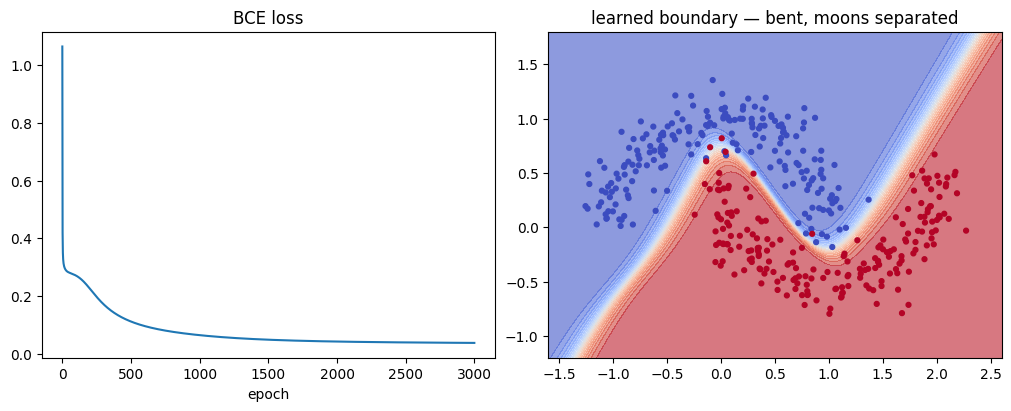

In [4]:
net = TwoLayerNet(2, 16, seed=1)
history = []
for epoch in range(3000):
    _, _, y_hat = net.forward(X)
    history.append(net.loss(y, y_hat))
    net.step(X, y, lr=0.5)

acc = ((net.forward(X)[2] > 0.5) == y).mean()
print(f"final loss {history[-1]:.4f} | train accuracy {acc:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].plot(history); axes[0].set_title("BCE loss"); axes[0].set_xlabel("epoch")
xx, yy = np.meshgrid(np.linspace(-1.6, 2.6, 200), np.linspace(-1.2, 1.8, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = net.forward(grid)[2].reshape(xx.shape)
axes[1].contourf(xx, yy, Z, levels=20, alpha=0.6, cmap="coolwarm")
axes[1].scatter(X[:, 0], X[:, 1], c=y.ravel(), s=12, cmap="coolwarm")
axes[1].set_title("learned boundary — bent, moons separated")
plt.show()

## Q5 — Vanishing/Exploding Gradients: the Multiplicative Chain

Backprop multiplies Jacobians layer by layer; if each has spectral norm < 1 the gradient **vanishes** geometrically (deep nets die silently), > 1 it **explodes**. The historical fixes (worth the two sentences): careful init (Xavier for tanh — variance 2/(n_in+n_out); He for ReLU — 2/n_in), normalized activations (batch/layer norm), residual connections (the identity shortcut gives gradient a clean path — *the* reason 100+ layer nets train). ReLU itself was part of the fix: its derivative is 0 or 1, no saturation on the positive side — with its own cost, **dying ReLU** (negative inputs stuck at 0 forever; LeakyReLU/GELU patch it).

In [5]:
# feel the chain: gradient magnitude through 20 sigmoid layers vs ReLU-with-residual
def sigmoid(z): return 1 / (1 + np.exp(-z))

rng = np.random.default_rng(0)
g = 1.0
for layer in range(20):
    g = g * rng.uniform(0.1, 0.9)          # sigmoid Jacobian entries < 1
print(f"gradient after 20 sigmoid-like layers: {g:.2e}   <- vanished")

g = 1.0
for layer in range(20):
    g = g * rng.uniform(0.9, 1.4)          # residual path keeps factors ~1
print(f"gradient with residual-scale factors: {g:.2e}   <- alive")

gradient after 20 sigmoid-like layers: 2.59e-08   <- vanished
gradient with residual-scale factors: 2.40e+01   <- alive


## Q6 — Batch Norm, Dropout, and the Regularization Stack

**Batch norm**: normalize each activation to zero-mean/unit-var *per mini-batch*, then learnable scale/shift. Effect: smoother loss surface (larger learning rates tolerate), internal-covariate-shift story (the original paper's framing — now contested; the smoother-optimization explanation is the modern one), mild regularization from batch noise. Inference uses running statistics — that train/inference asymmetry is an interview favorite. **Dropout**: zero units with probability p each training step, scale by 1/(1−p) at inference (inverted dropout) — an implicit ensemble of subnetworks. **The stack answer:** "augmentation + early stopping + weight decay first; dropout 0.1–0.5 in dense layers; batch/layer norm for optimization, not just regularization."**

In [6]:
# inverted dropout, written the way interviewers want to see it
def dropout_train(a, p, rng):
    mask = (rng.random(a.shape) >= p) / (1 - p)   # drop + rescale in one step
    return a * mask

rng = np.random.default_rng(0)
a = np.ones((1000, 200))
for p in (0.2, 0.5):
    out = dropout_train(a, p, rng)
    print(f"dropout p={p}: mean {out.mean():.3f}, std {out.std():.3f}  (input mean 1.0 — preserved by the 1/(1-p) scaling)")

dropout p=0.2: mean 1.000, std 0.500  (input mean 1.0 — preserved by the 1/(1-p) scaling)
dropout p=0.5: mean 1.000, std 1.000  (input mean 1.0 — preserved by the 1/(1-p) scaling)


## Q7 — Optimizers and LR Schedules for Deep Nets (the Follow-Up Chain)

Adam(β₁=0.9, β₂=0.999) is the default; SGD+momentum sometimes generalizes better on vision (the sharp-vs-flat minima debate — name it). **Warmup** (ramp up over first epochs) stabilizes early training when Adam's v̂ estimates are noisy. **Cosine decay** or step schedules anneal for late precision. The batch-size relationship: linear scaling rule with warmup. This is all in the [Gradient Descent notebook](../3.%20Machine%20Learning%20Interviews/Gradient%20Descent%20from%20Scratch.ipynb) with implementations — link it if the interviewer wants depth.

## Q8 — CNNs, RNNs, Attention: One Breath Each

- **CNN** — weight sharing + locality: a filter slides over the input, so translation-invariant patterns are learned with orders of magnitude fewer parameters than dense; pooling adds scale tolerance. Think: "the same edge detector at every position."
- **RNN/LSTM** — recurrence carries a hidden state across time; LSTM's gates (input/forget/output) learn what to remember/forget, fighting vanishing gradients. Today: legacy for most sequence work, still relevant for streaming/low-latency edge cases.
- **Attention / Transformers** — every token attends to every other: Attention(Q,K,V) = softmax(QKᵀ/√d)V. Parallel over sequence (vs RNN's sequential), path length between any two tokens is O(1) (long-range dependencies), scales with compute. Positional encodings inject order. *The* architecture of the LLM era — the [NLP notebook](NLP%20Interview%20Questions.ipynb) does the attention math.
- **Batch vs layer norm in each** — CNNs: batch norm; RNNs/transformers: layer norm (batch varies over time).

In [7]:
# attention in six lines, executed
rng = np.random.default_rng(0)
d, T = 8, 5
Q, K, V = (rng.normal(size=(T, d)) for _ in range(3))

scores = Q @ K.T / np.sqrt(d)          # (T, T) token-token compatibility
weights = np.exp(scores) / np.exp(scores).sum(-1, keepdims=True)
out = weights @ V                      # (T, d): each output is a weighted mix of values
print("attention weights row 0 (how much token 0 attends to each token):")
print(weights[0].round(3))
print(f"\neach row sums to {weights[0].sum():.1f} — a learned, input-dependent weighted average")

attention weights row 0 (how much token 0 attends to each token):
[0.367 0.063 0.113 0.115 0.342]

each row sums to 1.0 — a learned, input-dependent weighted average


## Q9 — Quick-Fire DL Round

| Question | The 15-second answer |
| --- | --- |
| Why ReLU over sigmoid? | No positive-side saturation (no vanishing gradient), cheap derivative, sparsity; caveat: dying ReLU → LeakyReLU/GELU |
| Xavier vs He init? | Xavier for tanh/sigmoid (variance 2/(fan_in+fan_out)), He for ReLU (2/fan_in) — keeps activation variance ~1 across depth |
| What does 1×1 convolution do? | Channel mixing/dimensionality change at one spatial position — cheap feature combination, the Network-in-Network trick |
| Why pad convolutions? | Preserve spatial size; 'same' padding keeps feature maps aligned across layers |
| What's a residual connection? | y = F(x) + x — identity shortcut; gradients flow through the addition, enabling very deep nets |
| Encoder-decoder with skip connections? | U-Net: downsampling for context, skips for localization — the segmentation workhorse |
| Overfitting in a CNN — first three moves? | Augmentation, then dropout/weight decay, then smaller model — in that order |
| Loss for imbalanced segmentation? | Dice loss (directly optimizes overlap) or focal loss (down-weights easy negatives) — both handle the class imbalance in pixel space |
| What's mixed precision? | fp16/bf16 compute with fp32 master weights — 2-3x speed on tensor cores; loss scaling for fp16 stability |